# C3 DistilBERT

Ba seed 42, 123, 2026, cùng trainer với C1/C2. Đầu ra đã được chạy và lưu. Run All kiểm cấu hình, tính lại metric, chạy suy luận và phân tích lỗi; không train lại mô hình. Lệnh huấn luyện khi cần một thí nghiệm riêng: `python -m scripts.transformers.train_transformer --architecture distilbert --seed 42 --device cuda --output-root artifacts/my_experiment`. Không ghi đè bộ kết quả của báo cáo.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root, benchmark, replay_split
from src.models.transformer import run_folder, load_transformer_run, METRIC_NAMES
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.datasets.goemotions import multi_hot
ARTIFACTS = artifacts_root()
verified, frames, labels = benchmark(str(ARTIFACTS))
SEEDS = (42, 123, 2026)
pd.set_option('display.max_columns', 20)
print('Python:', sys.version.split()[0])
print('Đã kiểm: 72 dòng kết quả và 9 checkpoint; ba seed cho mỗi C.')

PASS A: 12 dòng từ scores thật


PASS B: 6 dòng từ scores thật


PASS C: bert seed 42


PASS C: bert seed 123


PASS C: bert seed 2026


...

PASS C: roberta seed 2026


PASS C: distilbert seed 42


PASS C: distilbert seed 123


PASS C: distilbert seed 2026


Python: 3.13.9
Đã kiểm: 72 dòng kết quả và 9 checkpoint; ba seed cho mỗi C.


## 1 Cấu hình và môi trường thực tế

In [2]:
runs={s:load_transformer_run(run_folder(ARTIFACTS,'distilbert',s),require_full=True) for s in SEEDS}
display(pd.DataFrame([{'seed':s,'selected_epoch':m['selected_epoch'],**m['config'],**m['environment']} for s,m in runs.items()])[['seed','epochs','learning_rate','batch_size','max_length','warmup_ratio','weighted','selected_epoch','python','torch','transformers','cuda_runtime','gpu','amp_fp16']])
assert all(m['sizes']=={'train':43410,'validation':5426} for m in runs.values())
assert all(m['config']['learning_rate']==2e-5 and m['config']['epochs']==3 for m in runs.values())

,seed,epochs,learning_rate,batch_size,max_length,warmup_ratio,weighted,selected_epoch,python,torch,transformers,cuda_runtime,gpu,amp_fp16
0,42,3,0.00002,16,128,0.1,False,3,3.13.9,2.13.0+cu130,4.57.6,13.0,NVIDIA GeForce RTX 5060 Laptop GPU,True
1,123,3,0.00002,16,128,0.1,False,3,3.13.9,2.13.0+cu130,4.57.6,13.0,NVIDIA GeForce RTX 5060 Laptop GPU,True
2,2026,3,0.00002,16,128,0.1,False,3,3.13.9,2.13.0+cu130,4.57.6,13.0,NVIDIA GeForce RTX 5060 Laptop GPU,True


## 2 Đường học và checkpoint
Loss train trong quá trình tối ưu có dropout và AMP. Macro-F1 validation đo tại 0,5; đây là tiêu chí chọn checkpoint.

,seed,epoch,train_loss,macro_f1,micro_f1,epoch_seconds,validation_seconds,validation_bce_eval,learning_rate_end
0,42,1,0.163077,0.261312,0.509674,333.873194,11.209145,0.091569,1.481441e-05
1,42,2,0.085887,0.370888,0.556782,332.417883,13.614714,0.085281,7.407205e-06
2,42,3,0.076044,0.401835,0.566773,388.480603,14.491221,0.084445,2.729258e-09
3,123,1,0.162694,0.268426,0.515136,354.514095,14.493418,0.091872,1.481441e-05
4,123,2,0.086130,0.383196,0.566568,269.433095,5.754162,0.084612,7.407205e-06
5,123,3,0.076093,0.413226,0.573884,193.302809,6.041593,0.084083,2.729258e-09
6,2026,1,0.162151,0.248185,0.518384,360.798486,12.643817,0.090772,1.481441e-05
7,2026,2,0.086103,0.380394,0.562620,340.554482,10.954531,0.084715,7.407205e-06
8,2026,3,0.075887,0.404164,0.572821,329.507953,7.531245,0.084298,2.729258e-09


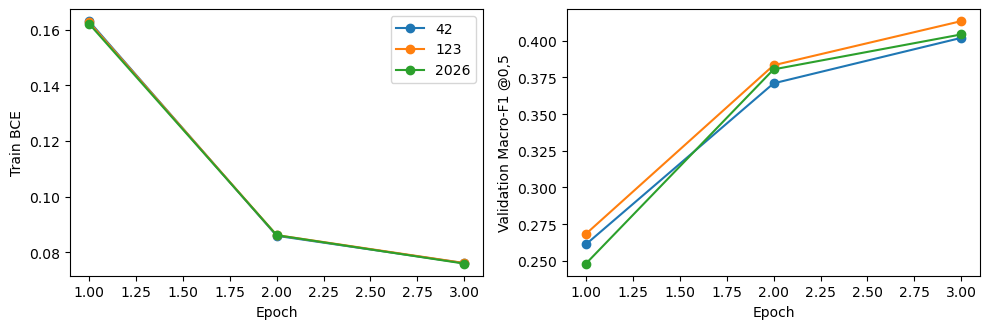

Seed đại diện theo validation: 123


In [3]:
history=pd.DataFrame([dict(seed=s,**h) for s,m in runs.items() for h in m['history']])
display(history)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
for s,g in history.groupby('seed'):
    axes[0].plot(g.epoch,g.train_loss,'-o',label=str(s))
    axes[1].plot(g.epoch,g.macro_f1,'-o',label=str(s))
axes[0].set(xlabel='Epoch',ylabel='Train BCE');axes[1].set(xlabel='Epoch',ylabel='Validation Macro-F1 @0,5')
axes[0].legend();fig.tight_layout();plt.show()
representative=max(SEEDS,key=lambda s:(runs[s]['metrics']['macro_f1'],-s))
print('Seed đại diện theo validation:',representative)

## 3 Tokenizer head và BCE
Tokenizer WordPiece uncased thuộc đúng checkpoint. Ví dụ forward dưới đây dùng bốn câu train, float32 và eval mode, không cập nhật trọng số.

In [4]:
import torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification
torch.set_num_threads(4)
folder=run_folder(ARTIFACTS,'distilbert',representative)
tokenizer=AutoTokenizer.from_pretrained(folder/'checkpoint',local_files_only=True)
model=AutoModelForSequenceClassification.from_pretrained(folder/'checkpoint',local_files_only=True).eval()
sample=frames['train'].iloc[:4]
inputs=tokenizer(sample.text.tolist(),padding=True,truncation=True,max_length=128,return_tensors='pt')
y=torch.tensor(multi_hot(sample.labels.tolist()),dtype=torch.float32)
with torch.inference_mode():
    logits=model(**inputs).logits
    loss=torch.nn.functional.binary_cross_entropy_with_logits(logits,y)
assert logits.shape==y.shape==(4,28)
print('Tokens câu đầu:',tokenizer.convert_ids_to_tokens(inputs['input_ids'][0]))
print('Input:',tuple(inputs['input_ids'].shape),'Logits:',tuple(logits.shape),'BCE:',loss.item())
del model

Tokens câu đầu: ['[CLS]', 'my', 'favourite', 'food', 'is', 'anything', 'i', 'didn', "'", 't', 'have', 'to', 'cook', 'myself', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
Input: (4, 24) Logits: (4, 28) BCE: 0.05665384605526924


## 4 Kết quả validation test và mean ± std khớp báo cáo
Ngưỡng riêng đã được chọn chỉ trên validation. Mỗi nhóm phải đủ ba seed, std dùng ddof=1.

In [5]:
records=pd.DataFrame(verified['records']);means=pd.DataFrame(verified['averages'])
c3=records[records.system=='C_distilbert']
display(c3[c3.threshold_mode.isin(['fixed','tuned'])])
display(means[(means.system=='C_distilbert')&means.threshold_mode.isin(['fixed','tuned'])])
for (split,mode),g in c3.groupby(['split','threshold_mode']):
    row=means[(means.system=='C_distilbert')&(means.split==split)&(means.threshold_mode==mode)].iloc[0]
    assert set(g.seed.astype(int))==set(SEEDS)
    for k in METRIC_NAMES:
        np.testing.assert_allclose([g[k].mean(),g[k].std(ddof=1)],[row[k+'_mean'],row[k+'_std']],atol=1e-12,rtol=0)
print('PASS: kết quả và std khớp bộ số dùng cho báo cáo.')

,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss
54,C_distilbert,42.0,validation,fixed,5426,0.401835,0.566773,0.574811,0.342263,0.704048,0.474295,0.030449
56,C_distilbert,42.0,validation,tuned,5426,0.504146,0.601041,0.524867,0.526146,0.545014,0.669906,0.037347
57,C_distilbert,42.0,test,fixed,5427,0.409721,0.571483,0.585667,0.352570,0.710860,0.477801,0.029844
59,C_distilbert,42.0,test,tuned,5427,0.480432,0.588951,0.495697,0.514423,0.528290,0.665350,0.038682
60,C_distilbert,123.0,validation,fixed,5426,0.413226,0.573884,0.582161,0.351340,0.710125,0.481505,0.030027
62,C_distilbert,123.0,validation,tuned,5426,0.503118,0.604302,0.528045,0.522263,0.560075,0.656113,0.036083
63,C_distilbert,123.0,test,fixed,5427,0.415635,0.574858,0.595203,0.356566,0.715361,0.480487,0.029601
65,C_distilbert,123.0,test,tuned,5427,0.482093,0.598433,0.492933,0.511131,0.548919,0.657766,0.036767
66,C_distilbert,2026.0,validation,fixed,5426,0.404164,0.572821,0.583353,0.342758,0.712354,0.478997,0.030001
68,C_distilbert,2026.0,validation,tuned,5426,0.515938,0.600410,0.512139,0.544068,0.547119,0.665204,0.037182


,system,split,threshold_mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,micro_precision_mean,micro_precision_std,micro_recall_mean,micro_recall_std,hamming_loss_mean,hamming_loss_std
30,C_distilbert,validation,fixed,3,0.406409,0.006018,0.571159,0.003836,0.580108,0.004626,0.345454,0.005104,0.708843,0.004299,0.478265,0.003660,0.030159,0.000251
32,C_distilbert,validation,tuned,3,0.507734,0.007123,0.601918,0.002089,0.521683,0.008417,0.530826,0.011631,0.550736,0.008156,0.663741,0.007012,0.036871,0.000687
33,C_distilbert,test,fixed,3,0.411556,0.003538,0.573120,0.001690,0.591204,0.004951,0.353504,0.002718,0.712432,0.002539,0.479381,0.001404,0.029743,0.000127
35,C_distilbert,test,tuned,3,0.486632,0.009338,0.593544,0.004748,0.498976,0.008190,0.517908,0.009039,0.538451,0.010318,0.661347,0.003810,0.037732,0.000958


PASS: kết quả và std khớp bộ số dùng cho báo cáo.


## 5 Suy luận thật từ ba checkpoint
Chạy đủ validation và test. Không chọn lại checkpoint hay ngưỡng. Sai lệch số học được hiển thị riêng.

In [6]:
fresh=pd.concat([replay_split(ARTIFACTS,'C_distilbert',s,split) for s in SEEDS for split in ('validation','test')],ignore_index=True)
assert len(fresh)==18
display(fresh[fresh.threshold_mode.isin(['fixed','tuned'])])
print('Sai lệch score lớn nhất:',fresh.score_max_abs_diff.max())

,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,metric_max_abs_diff,score_max_abs_diff,score_tolerance,changed_label_decisions,exact_metric_match
0,C_distilbert,42,validation,fixed,5426,0.401835,0.566773,0.574811,0.342263,0.704048,0.474295,0.030449,0.0,0.0,0.005,0,True
2,C_distilbert,42,validation,tuned,5426,0.504146,0.601041,0.524867,0.526146,0.545014,0.669906,0.037347,0.0,0.0,0.005,0,True
3,C_distilbert,42,test,fixed,5427,0.409721,0.571483,0.585667,0.352570,0.710860,0.477801,0.029844,0.0,0.0,0.005,0,True
5,C_distilbert,42,test,tuned,5427,0.480432,0.588951,0.495697,0.514423,0.528290,0.665350,0.038682,0.0,0.0,0.005,0,True
6,C_distilbert,123,validation,fixed,5426,0.413226,0.573884,0.582161,0.351340,0.710125,0.481505,0.030027,0.0,0.0,0.005,0,True
8,C_distilbert,123,validation,tuned,5426,0.503118,0.604302,0.528045,0.522263,0.560075,0.656113,0.036083,0.0,0.0,0.005,0,True
9,C_distilbert,123,test,fixed,5427,0.415635,0.574858,0.595203,0.356566,0.715361,0.480487,0.029601,0.0,0.0,0.005,0,True
11,C_distilbert,123,test,tuned,5427,0.482093,0.598433,0.492933,0.511131,0.548919,0.657766,0.036767,0.0,0.0,0.005,0,True
12,C_distilbert,2026,validation,fixed,5426,0.404164,0.572821,0.583353,0.342758,0.712354,0.478997,0.030001,0.0,0.0,0.005,0,True
14,C_distilbert,2026,validation,tuned,5426,0.515938,0.600410,0.512139,0.544068,0.547119,0.665204,0.037182,0.0,0.0,0.005,0,True


Sai lệch score lớn nhất: 0.0


## 6 Nhãn hiếm ma trận lỗi và ví dụ
Seed đại diện lấy từ validation. Ma trận là số cặp FN–FP trên cùng câu; mỗi câu có thể đóng góp nhiều ô.

,architecture,seed,category,error_samples,total_samples,eligible_samples,fraction_all_samples,fraction_eligible
0,distilbert,123,partial_multi_label,449,5427,837,0.082734,0.536440
1,distilbert,123,rare_false_negative,90,5427,93,0.016584,0.967742
2,distilbert,123,missed_extra_pair,1140,5427,5427,0.210061,0.210061


,architecture,seed,label,train_positive_count,evaluation_positive_count,tp,fn,fp,precision,recall,f1
0,distilbert,123,grief,77,6,0,6,0,0.00,0.000000,0.000000
1,distilbert,123,pride,111,16,0,16,0,0.00,0.000000,0.000000
2,distilbert,123,relief,153,11,0,11,0,0.00,0.000000,0.000000
3,distilbert,123,nervousness,164,23,0,23,0,0.00,0.000000,0.000000
4,distilbert,123,embarrassment,303,37,3,34,1,0.75,0.081081,0.146341


,id,text,true_labels,predicted_labels
0,eczj48j,This!!! 🐃 and 💍 for your hard work!,"[""admiration"", ""excitement"", ""neutral""]","[""admiration""]"
1,eczje98,I love this! It's nice to hear of a positive o...,"[""admiration"", ""love""]","[""love""]"
2,eczs4ty,I'm sorry to hear this. I hope you can find so...,"[""optimism"", ""remorse""]","[""optimism""]"
3,ed0jr9i,Try nonchalantly handing them your card as if ...,"[""embarrassment""]",[]
4,ed0wflq,I was teased for being a virgin when I was a 6...,"[""embarrassment""]",[]
5,ed157d1,I feel a sense of unease tbh,"[""nervousness""]",[]
6,eczcvgx,"I always plan that, my wife usually has other ...","[""neutral""]","[""approval""]"
7,eczd32o,This thread was actually inspired by one of yo...,"[""admiration""]","[""neutral""]"
8,eczez7j,Nah... i think he made around 90... i tried se...,"[""neutral""]","[""anger""]"


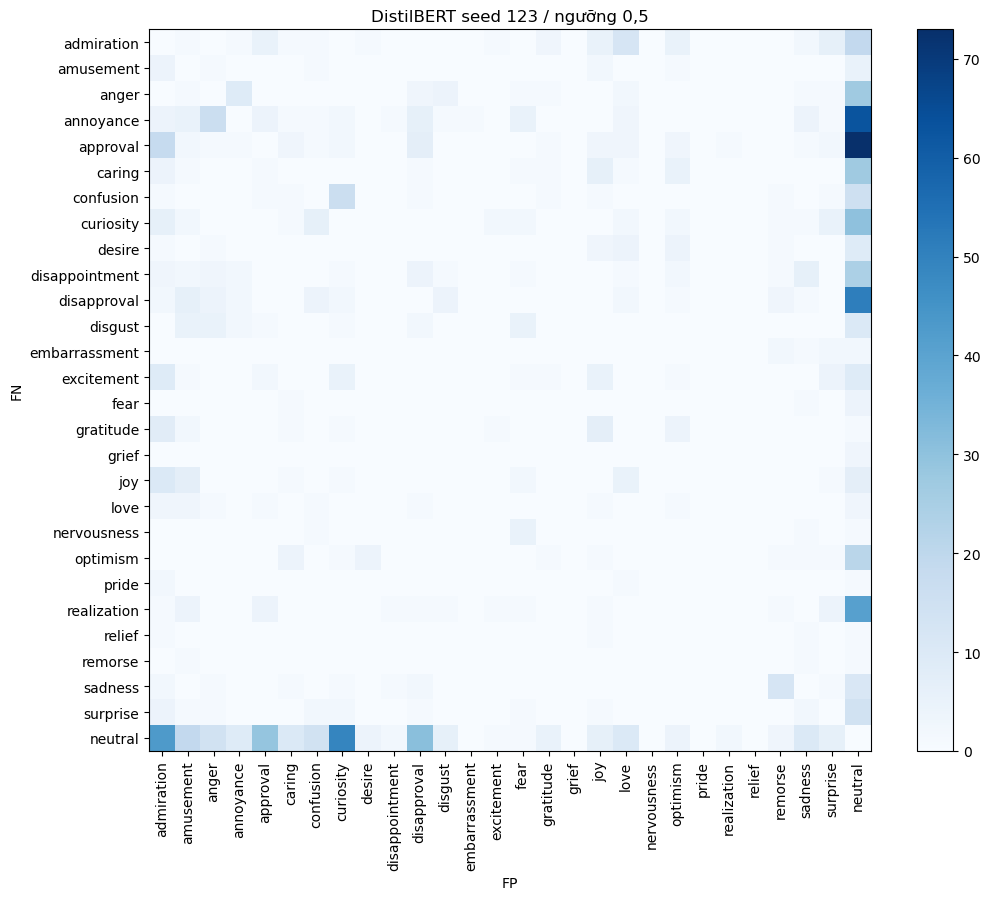

In [7]:
from src.models.baseline import load_aligned_scores
from scripts.analysis.analyze_project_errors import analyze_arrays
support=multi_hot(frames['train'].labels.tolist()).sum(0)
rare_ids=np.argsort(support,kind='stable')[:5]
folder=run_folder(ARTIFACTS,'distilbert',representative)
scores=load_aligned_scores(folder/'test_scores.npz',frames['test'].id,labels)
counts,pairs,rare,examples=analyze_arrays(frames['test'],labels,rare_ids,support,{'distilbert':runs[representative]},{'distilbert':scores},{'distilbert':.5},3)
display(pd.DataFrame(counts));display(pd.DataFrame(rare));display(pd.DataFrame(examples)[['id','text','true_labels','predicted_labels']])
matrix=np.zeros((28,28),dtype=int)
for r in pairs:matrix[labels.index(r['missed_label']),labels.index(r['extra_label'])]=r['sample_count']
fig,ax=plt.subplots(figsize=(11,9));im=ax.imshow(matrix,cmap='Blues');ax.set_xticks(range(28),labels,rotation=90);ax.set_yticks(range(28),labels);ax.set(xlabel='FP',ylabel='FN',title=f'DistilBERT seed {representative} / ngưỡng 0,5');fig.colorbar(im,ax=ax);fig.tight_layout();plt.show()

## 7 Demo câu mới
Dùng đúng checkpoint đại diện và ngưỡng riêng trong protocol.

In [8]:
from src.apps.model_selector import ModelSelector
selector=ModelSelector(ARTIFACTS,ARTIFACTS/'data/processed/transformers/selected_model.json',device='auto')
for mode in ('fixed','tuned'):
    message,rows=selector.predict('I was worried, but your help made me feel so relieved.','distilbert',mode)
    print(mode,message);display(pd.DataFrame(rows,columns=['label','score','threshold','selected']).head(8))
del selector
print('Hoàn tất C3: ba checkpoint và sáu lượt suy luận đầy đủ; không train trong Run All.')

fixed **Mô hình:** C3 · DistilBERT · seed 123

**Chưa có nhãn nào đạt ngưỡng.** Không tự suy ra neutral trong trường hợp này.


,label,score,threshold,selected
0,sadness,0.3013,0.5,
1,caring,0.1720,0.5,
2,joy,0.1072,0.5,
3,remorse,0.0839,0.5,
4,gratitude,0.0826,0.5,
5,fear,0.0649,0.5,
6,nervousness,0.0562,0.5,
7,realization,0.0526,0.5,


tuned **Mô hình:** C3 · DistilBERT · seed 123

**Chưa có nhãn nào đạt ngưỡng.** Không tự suy ra neutral trong trường hợp này.


,label,score,threshold,selected
0,sadness,0.3013,0.35,
1,caring,0.1720,0.20,
2,joy,0.1072,0.45,
3,remorse,0.0839,0.25,
4,gratitude,0.0826,0.60,
5,fear,0.0649,0.15,
6,nervousness,0.0562,0.15,
7,realization,0.0526,0.25,


Hoàn tất C3: ba checkpoint và sáu lượt suy luận đầy đủ; không train trong Run All.
